# Activité Pratique N°4 — Architecture Transformer
## Partie 1 — Étape 2 : Modèle RNN

**IA Générative Multi Modale — 5IAD G1, EMSI** · Étudiant : BENHAYOUN SADAFI Mohamed

Créer, entraîner et tester un RNN qui prédit la valeur suivante d'une séquence de 10 éléments.

> 🔁 **Code refait** — le dataset est de l'étape 1 (notebook `1 - Dataset serie temporelle`).
> Chaque notebook est indépendant : il recrée ce dont il a besoin au lieu de dépendre d'un autre notebook.

In [1]:
import json
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn


def fixer_graine(graine=42):
    random.seed(graine)
    np.random.seed(graine)
    torch.manual_seed(graine)


fixer_graine()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| appareil :", device,
      f"({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "")

PyTorch 2.14.1+cu126 | appareil : cuda (NVIDIA GeForce MX450)


In [2]:
# 200 valeurs de sin(x) entre 0 et 20, fenêtres de 10 valeurs -> valeur suivante
x = torch.linspace(0, 20, 200)
s = torch.sin(x)
longueur_sequence = 10

X = torch.stack([s[i:i + longueur_sequence] for i in range(len(s) - longueur_sequence)]).unsqueeze(-1)  # (190, 10, 1)
Y = torch.stack([s[i + longueur_sequence] for i in range(len(s) - longueur_sequence)]).unsqueeze(-1)    # (190, 1)

X_train, Y_train = X[:150], Y[:150]
X_test, Y_test = X[150:], Y[150:]
print("Train :", tuple(X_train.shape), tuple(Y_train.shape), "| Test :", tuple(X_test.shape), tuple(Y_test.shape))

Train : (150, 10, 1) (150, 1) | Test : (40, 10, 1) (40, 1)


> 🔁 **Code refait** — fonctions d'entraînement et d'affichage communes aux notebooks 2, 3 et 4 (même protocole : Adam `lr=0.01`, MSE, 300 époques).

In [3]:
FICHIER_RESULTATS = Path("resultats_partie1.json")   # partagé avec le notebook 4 pour la comparaison


def nb_parametres(modele):
    return sum(p.numel() for p in modele.parameters())


def entrainer_serie(modele, epochs=300, lr=0.01):
    # Même protocole pour les trois modèles : Adam, MSE, 300 époques, un seul lot.
    fixer_graine()
    modele = modele.to(device)
    optimiseur = torch.optim.Adam(modele.parameters(), lr=lr)
    critere = nn.MSELoss()
    Xtr, Ytr = X_train.to(device), Y_train.to(device)
    pertes = []
    for epoch in range(epochs):
        modele.train()
        perte = critere(modele(Xtr), Ytr)
        optimiseur.zero_grad()
        perte.backward()
        optimiseur.step()
        pertes.append(perte.item())
        if (epoch + 1) % 50 == 0:
            print(f"Époque {epoch + 1:3d} | MSE entraînement : {perte.item():.6f}")
    modele.eval()
    with torch.no_grad():
        predictions = modele(X_test.to(device)).cpu()
    mse_test = critere(predictions, Y_test).item()
    print(f"\nMSE test : {mse_test:.6f}")
    print(f"Premier exemple de test : réel = {Y_test[0].item():.4f} | prédit = {predictions[0].item():.4f}")
    return predictions, mse_test, pertes


def tracer_predictions(predictions, nom):
    plt.figure(figsize=(12, 4))
    plt.plot(Y_test.numpy().ravel(), label="Valeurs réelles", color="tab:blue", linewidth=2)
    plt.plot(predictions.numpy().ravel(), label=f"Prédictions du {nom}", color="tab:red", linestyle="--", linewidth=2)
    plt.title(f"{nom} : valeurs réelles et prédictions sur le test")
    plt.xlabel("Indice de l'exemple de test")
    plt.ylabel("Valeur")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


def sauvegarder_resultat(nom, mse_test, modele, pertes, predictions):
    resultats = json.loads(FICHIER_RESULTATS.read_text(encoding="utf-8")) if FICHIER_RESULTATS.exists() else {}
    resultats[nom] = {"mse_test": mse_test, "parametres": nb_parametres(modele), "pertes": pertes,
                      "predictions": predictions.numpy().ravel().tolist()}
    FICHIER_RESULTATS.write_text(json.dumps(resultats), encoding="utf-8")
    print(f"Résultats du {nom} enregistrés dans {FICHIER_RESULTATS}")

### Architecture

Une même cellule RNN de **16 unités** lit les 10 valeurs une à une. À chaque instant :

$$h_t = \tanh(W_{ih}x_t + W_{hh}h_{t-1} + b), \qquad h_0 = 0$$

Le dernier état caché $h_{10}$ passe dans une couche `Linear(16 → 1)` qui donne la prédiction $\hat y$.

```
h0=0 → [RNN 16 unités] → h1 → [RNN 16 unités] → h2 → … → [RNN 16 unités] → h10 → Linear(16→1) → ŷ
            ↑x1                     ↑x2                          ↑x10
```
Les cellules dessinées sont **une seule couche réutilisée dans le temps** (mêmes poids à chaque instant).

In [4]:
class ModeleRNN(nn.Module):
    def __init__(self, unites=16):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=unites, batch_first=True)
        self.sortie = nn.Linear(unites, 1)

    def forward(self, x):                    # x : (B, 10, 1)
        etats, _ = self.rnn(x)               # (B, 10, 16) ; h0 = 0 par défaut
        return self.sortie(etats[:, -1, :])  # dernier état h10 -> (B, 1)


fixer_graine()
rnn = ModeleRNN()
print(rnn)
print("Paramètres :", nb_parametres(rnn))

ModeleRNN(
  (rnn): RNN(1, 16, batch_first=True)
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)


Paramètres : 321


### Entraînement et test

Époque  50 | MSE entraînement : 0.001277


Époque 100 | MSE entraînement : 0.000504


Époque 150 | MSE entraînement : 0.000223


Époque 200 | MSE entraînement : 0.000103
Époque 250 | MSE entraînement : 0.000049


Époque 300 | MSE entraînement : 0.000025

MSE test : 0.000028
Premier exemple de test : réel = -0.3639 | prédit = -0.3601


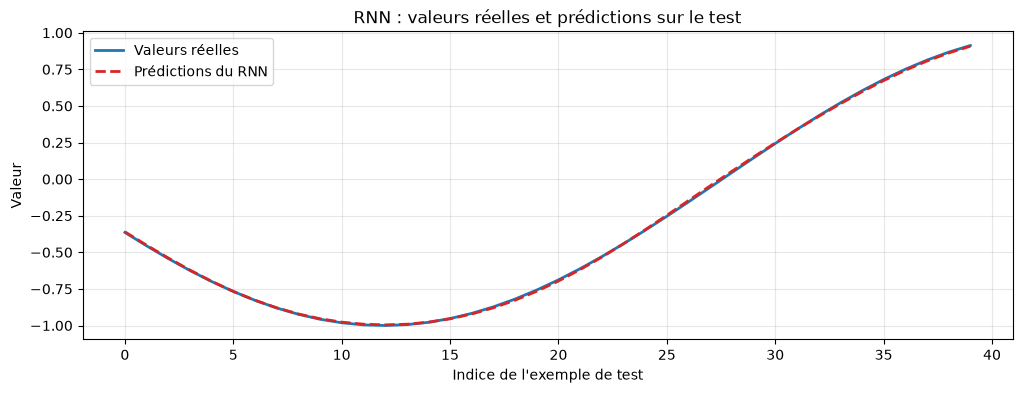

Résultats du RNN enregistrés dans resultats_partie1.json


In [5]:
pred_rnn, mse_rnn, pertes_rnn = entrainer_serie(rnn)
tracer_predictions(pred_rnn, "RNN")
sauvegarder_resultat("RNN", mse_rnn, rnn, pertes_rnn, pred_rnn)

**Limite principale :** le gradient doit traverser tous les pas de temps (rétropropagation à travers le temps) ; sur de longues séquences il peut **disparaître ou exploser**, et le calcul est séquentiel (difficile à paralléliser).
Ici la séquence ne fait que 10 pas, donc le RNN apprend bien la sinusoïde.